# НИРМ 4 — предлагаемый метод (пол на уровне отведений) против известных подходов

Анализ запусков `nirm4_sexaware_colab.ipynb` и `nirm4_method_colab.ipynb` (Google Colab, Tesla T4), CNN-LSTM,
по 5 seed на вариант, общая папка `results_nirm4/`:

| вариант | что меняется | источник идеи |
|---|---|---|
| `base` | ничего (CNN-LSTM недели 8) | — |
| `demo`, `groupw`, `demo_groupw` | возраст/пол на входе головы, веса по полу | первый эксперимент НИРМ 4 |
| `leadgate` | **предлагаемый метод:** пол и возраст задают усиление каждого отведения | неделя 9: асимметрия вклада отведений |
| `film` | пол и возраст модулируют каналы свёрточного стебля | FiLM, Perez et al. (2018) |
| `sexnorm` | нормировка отведений статистикой своего пола | гипотеза амплитуды |
| `adv` | adversarial debiasing: из представления удаляется информация о поле | Ganin & Lempitsky (2015) |

**Критерий успеха (тот же, что в первом эксперименте, задан заранее):** разрыв macro-AUC и AUC MI
«женщины − мужчины» уменьшается, а общий macro-AUC не хуже базового больше чем на 0.005.

In [1]:
import glob
import json
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
from scipy.stats import rankdata

SEED = 42
CACHE = 'cache' + os.sep
FIG_DIR = CACHE + 'fig' + os.sep
RESULTS = os.environ.get('NIRM4_RESULTS', CACHE + 'results_nirm4' + os.sep)
assert glob.glob(RESULTS + '*.json'), 'скачайте results_nirm4/ из Google Drive'
plt.rcParams.update({'font.size': 9, 'axes.grid': True, 'grid.alpha': 0.3})
SUPERCLASSES = ['NORM', 'MI', 'STTC', 'CD', 'HYP']
K_MI = SUPERCLASSES.index('MI')
VARIANTS = ['base', 'demo', 'groupw', 'demo_groupw', 'film', 'leadgate', 'sexnorm', 'adv']
LABELS = {'base': 'CNN-LSTM (week 8)', 'demo': '+ age, sex at head', 'groupw': '+ sex-balanced loss',
          'demo_groupw': '+ both', 'film': 'FiLM on conv stem', 'leadgate': 'Sex-aware lead gating (proposed)',
          'sexnorm': 'sex-specific normalisation', 'adv': 'adversarial debiasing'}
COLORS = {'base': '#555555', 'demo': '#A6A6A6', 'groupw': '#A6A6A6', 'demo_groupw': '#A6A6A6',
          'film': '#4C72B0', 'leadgate': '#C98A1E', 'sexnorm': '#6B4E9B', 'adv': '#1B9E77'}

meta = np.load(CACHE + 'colab_meta_v2.npz')
Y, sex, split, has_label = meta['Y'].astype(int), meta['sex'], meta['split'], meta['has_label']
LEADS = json.load(open(CACHE + 'preprocessing.json'))['leads']

RUNS = {}
for f in sorted(glob.glob(RESULTS + '*.json')):
    info = json.load(open(f))
    z = np.load(f.replace('.json', '.npz'))
    RUNS[info['run_id']] = {**info, 's_val': z['s_val'], 's_test': z['s_test'], 'val_idx': z['val_idx'],
                            'test_idx': z['test_idx'], 'weights': f.replace('.json', '_weights.pt')}
first = next(iter(RUNS.values()))
va, te = first['val_idx'], first['test_idx']
assert all(np.array_equal(r['val_idx'], va) and np.array_equal(r['test_idx'], te) for r in RUNS.values())
VARIANTS = [v for v in VARIANTS if any(r['variant'] == v for r in RUNS.values())]
y_va, y_te, sex_va, sex_te = Y[va], Y[te], sex[va], sex[te]
BY_VARIANT = {v: sorted((r for r in RUNS.values() if r['variant'] == v), key=lambda r: r['seed']) for v in VARIANTS}
print({v: [r['seed'] for r in rs] for v, rs in BY_VARIANT.items()})
print('среда:', {r['env']['gpu'] for r in RUNS.values()})

{'base': [1, 2, 3, 4, 42], 'demo': [1, 2, 3, 4, 42], 'groupw': [1, 2, 3, 4, 42], 'demo_groupw': [1, 2, 3, 4, 42], 'film': [1, 2, 3, 4, 42], 'leadgate': [1, 2, 3, 4, 42], 'sexnorm': [1, 2, 3, 4, 42], 'adv': [1, 2, 3, 4, 42]}
среда: {'Tesla T4'}


## Протокол оценки (как на неделях 7–9 и в первом эксперименте)

In [2]:
N_BOOT = 1000
TARGET_SENS = 0.90


def auc_per_class(y, s):
    r = rankdata(s, axis=0)
    n_pos = y.sum(axis=0)
    n_neg = len(y) - n_pos
    return ((r * y).sum(axis=0) - n_pos * (n_pos + 1) / 2) / (n_pos * n_neg)


def macro_auc(y, s):
    return auc_per_class(y, s).mean()


def screening_thresholds(y_val, s_val, target=TARGET_SENS):
    th = []
    for k in range(y_val.shape[1]):
        pos_scores = np.sort(s_val[y_val[:, k] == 1, k])
        th.append(pos_scores[int(np.floor((1 - target) * len(pos_scores)))])
    return np.array(th)


def tests(v):
    return [r['s_test'] for r in BY_VARIANT[v]]


def gap_vector(fi, mi, scores):
    g = np.mean([auc_per_class(y_te[fi], s[fi]) - auc_per_class(y_te[mi], s[mi]) for s in scores], axis=0)
    return np.array([g.mean(), g[K_MI]])


F_IDX, M_IDX = np.where(sex_te == 'female')[0], np.where(sex_te == 'male')[0]
rng = np.random.default_rng(SEED)
BOOT_ALL = [rng.integers(0, len(y_te), len(y_te)) for _ in range(N_BOOT)]
BOOT_SEX = [(rng.choice(F_IDX, len(F_IDX)), rng.choice(M_IDX, len(M_IDX))) for _ in range(N_BOOT)]

## Задача 1. Общее качество и разрыв по полу

In [3]:
auc_boot = {v: np.array([np.mean([macro_auc(y_te[i], s[i]) for s in tests(v)]) for i in BOOT_ALL]) for v in VARIANTS}
gap_boot = {v: np.array([gap_vector(fi, mi, tests(v)) for fi, mi in BOOT_SEX]) for v in VARIANTS}
base_auc = np.mean([macro_auc(y_te, s) for s in tests('base')])

rows = []
for v in VARIANTS:
    auc = np.mean([macro_auc(y_te, s) for s in tests(v)])
    gap = gap_vector(F_IDX, M_IDX, tests(v))
    d_auc, d_gap = auc_boot[v] - auc_boot['base'], gap_boot[v] - gap_boot['base']
    rows.append({
        'variant': v, 'seeds': len(BY_VARIANT[v]), 'test macro-AUC': auc,
        'sd over seeds': np.std([macro_auc(y_te, s) for s in tests(v)], ddof=1),
        'Δ AUC': auc - base_auc, 'Δ AUC low': np.percentile(d_auc, 2.5), 'Δ AUC high': np.percentile(d_auc, 97.5),
        'gap macro': gap[0], 'gap macro low': np.percentile(gap_boot[v][:, 0], 2.5),
        'gap macro high': np.percentile(gap_boot[v][:, 0], 97.5),
        'Δ gap macro low': np.percentile(d_gap[:, 0], 2.5), 'Δ gap macro high': np.percentile(d_gap[:, 0], 97.5),
        'gap MI': gap[1], 'gap MI low': np.percentile(gap_boot[v][:, 1], 2.5),
        'gap MI high': np.percentile(gap_boot[v][:, 1], 97.5),
        'Δ gap MI low': np.percentile(d_gap[:, 1], 2.5), 'Δ gap MI high': np.percentile(d_gap[:, 1], 97.5),
        'female macro-AUC': np.mean([macro_auc(y_te[F_IDX], s[F_IDX]) for s in tests(v)]),
        'male macro-AUC': np.mean([macro_auc(y_te[M_IDX], s[M_IDX]) for s in tests(v)]),
        'female MI AUC': np.mean([auc_per_class(y_te[F_IDX], s[F_IDX])[K_MI] for s in tests(v)]),
        'male MI AUC': np.mean([auc_per_class(y_te[M_IDX], s[M_IDX])[K_MI] for s in tests(v)])})
summary = pd.DataFrame(rows).set_index('variant')
summary['non-inferior'] = summary['Δ AUC low'] > -0.005
summary['gap reduced (macro)'] = summary['Δ gap macro low'] > 0
summary['gap reduced (MI)'] = summary['Δ gap MI low'] > 0
print(summary.T.round(4).to_string())

variant                  base      demo    groupw demo_groupw      film  leadgate   sexnorm       adv
seeds                       5         5         5           5         5         5         5         5
test macro-AUC       0.932271  0.933693   0.93215    0.932958  0.933812  0.933457  0.931581  0.931559
sd over seeds        0.000842  0.000487   0.00196    0.000994  0.000254  0.000905  0.000918  0.001077
Δ AUC                     0.0  0.001422 -0.000121    0.000687   0.00154  0.001186  -0.00069 -0.000712
Δ AUC low                 0.0  0.000548 -0.001107   -0.000361  0.000326 -0.000066 -0.001759 -0.002245
Δ AUC high                0.0  0.002328   0.00083    0.001744  0.002823  0.002599  0.000327  0.000754
gap macro           -0.019017 -0.020053 -0.017757   -0.018528  -0.02013 -0.019051 -0.019745 -0.015369
gap macro low       -0.032321 -0.033048 -0.030821    -0.03133 -0.032624 -0.031691 -0.033706 -0.028091
gap macro high      -0.006635 -0.007176 -0.005035   -0.005651   -0.0078 -0.007225 

## Задача 2. Скрининг MI: общий порог и пороги с равной чувствительностью

In [4]:
def screening(v, policy):
    out = {'female sens': [], 'male sens': [], 'female spec': [], 'male spec': []}
    for r in BY_VARIANT[v]:
        common = screening_thresholds(y_va, r['s_val'])
        for g in ('female', 'male'):
            th = common if policy == 'common' else screening_thresholds(y_va[sex_va == g], r['s_val'][sex_va == g])
            m = sex_te == g
            pred, yk = r['s_test'][m, K_MI] >= th[K_MI], y_te[m, K_MI]
            out[f'{g} sens'].append(pred[yk == 1].mean())
            out[f'{g} spec'].append(1 - pred[yk == 0].mean())
    res = {k: np.mean(vals) for k, vals in out.items()}
    res['sens gap'], res['spec gap'] = res['female sens'] - res['male sens'], res['female spec'] - res['male spec']
    return res


sens = pd.DataFrame([{'variant': v, 'policy': p, **screening(v, p)} for v in VARIANTS for p in ('common', 'by sex')])
print(sens.set_index(['variant', 'policy']).round(3).to_string())

                    female sens  male sens  female spec  male spec  sens gap  spec gap
variant     policy                                                                    
base        common        0.891      0.919        0.796      0.800    -0.028    -0.004
            by sex        0.911      0.904        0.756      0.824     0.007    -0.068
demo        common        0.884      0.929        0.804      0.808    -0.045    -0.004
            by sex        0.914      0.913        0.753      0.832     0.001    -0.079
groupw      common        0.898      0.916        0.776      0.814    -0.018    -0.038
            by sex        0.907      0.908        0.754      0.823    -0.001    -0.069
demo_groupw common        0.899      0.915        0.764      0.818    -0.016    -0.054
            by sex        0.904      0.914        0.756      0.820    -0.010    -0.064
film        common        0.876      0.932        0.812      0.804    -0.056     0.008
            by sex        0.908      0.919 

## Задача 3. Что выучил предлагаемый модуль: усиление отведений у женщин и мужчин

Коэффициенты усиления g считаются по весам модуля при среднем возрасте обучающей выборки; сопоставляются с
отношением амплитуд (СКО) отведений у женщин и мужчин в обучающих фолдах 1–8.

In [5]:
def lead_gains(run, female):
    sd = torch.load(run['weights'], map_location='cpu')
    w1, b1, w2, b2 = (sd[f'gate.net.{k}'] for k in ('0.weight', '0.bias', '2.weight', '2.bias'))
    demo = torch.tensor([[0.0, float(female)]])
    return (2 * torch.sigmoid(torch.relu(demo @ w1.T + b1) @ w2.T + b2)).squeeze(0).numpy()


X_mm = np.load(CACHE + 'X100_bp05-40_crop.npy', mmap_mode='r')
tr = np.where((split == 'train') & has_label)[0]
amp = {g: np.asarray(X_mm[tr[sex[tr] == g]]).std(axis=(0, 1)) for g in ('female', 'male')}
leads_table = pd.DataFrame({'amplitude F/M': amp['female'] / amp['male']}, index=LEADS)
if 'leadgate' in BY_VARIANT:
    gf = np.array([lead_gains(r, True) for r in BY_VARIANT['leadgate']])
    gm = np.array([lead_gains(r, False) for r in BY_VARIANT['leadgate']])
    leads_table['gain female'] = gf.mean(0)
    leads_table['gain male'] = gm.mean(0)
    leads_table['gain F/M'] = (gf / gm).mean(0)
    leads_table['gain F/M sd'] = (gf / gm).std(0, ddof=1)
    leads_table['amplitude × gain F/M'] = leads_table['amplitude F/M'] * leads_table['gain F/M']
print(leads_table.round(3).to_string())

     amplitude F/M  gain female  gain male  gain F/M  gain F/M sd  amplitude × gain F/M
I            1.023        0.924      0.910     1.016        0.062                 1.040
II           1.032        0.947      0.970     0.977        0.068                 1.008
III          0.975        0.887      0.972     0.912        0.035                 0.889
AVR          1.043        0.990      0.933     1.062        0.031                 1.108
AVL          0.989        0.863      0.932     0.927        0.024                 0.917
AVF          0.997        0.941      0.991     0.949        0.034                 0.947
V1           0.884        1.143      1.132     1.010        0.009                 0.893
V2           0.832        1.223      1.066     1.147        0.018                 0.954
V3           0.791        1.017      0.958     1.061        0.020                 0.840
V4           0.812        0.957      0.934     1.025        0.032                 0.832
V5           0.873        0.953 

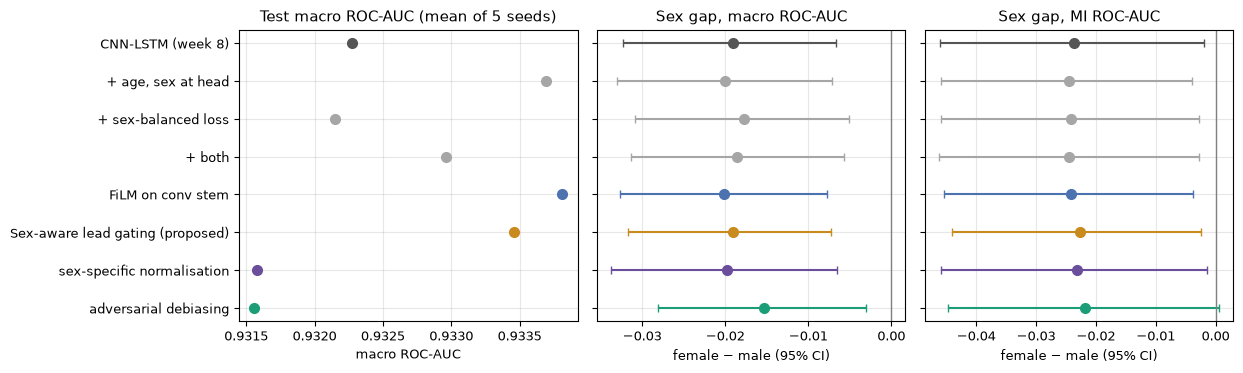

In [6]:
fig, ax = plt.subplots(1, 3, figsize=(12.5, 3.8), gridspec_kw={'width_ratios': [1.1, 1, 1]})
yy = np.arange(len(VARIANTS))[::-1]
for y_, v in zip(yy, VARIANTS):
    s = summary.loc[v]
    for a, col, low, high in ((ax[0], 'test macro-AUC', None, None), (ax[1], 'gap macro', 'gap macro low', 'gap macro high'),
                              (ax[2], 'gap MI', 'gap MI low', 'gap MI high')):
        if low:
            a.errorbar(s[col], y_, xerr=[[s[col] - s[low]], [s[high] - s[col]]], fmt='o', ms=7, capsize=3,
                       color=COLORS[v])
        else:
            a.plot(s[col], y_, 'o', ms=7, color=COLORS[v])
ax[0].set_yticks(yy, [LABELS[v] for v in VARIANTS])
ax[0].set(title='Test macro ROC-AUC (mean of 5 seeds)', xlabel='macro ROC-AUC')
for a, title in ((ax[1], 'Sex gap, macro ROC-AUC'), (ax[2], 'Sex gap, MI ROC-AUC')):
    a.axvline(0, color='gray', lw=1)
    a.set_yticks(yy, [''] * len(yy))
    a.set(title=title, xlabel='female − male (95% CI)')
ax[1].set_xticks(np.arange(-0.03, 0.001, 0.01))
plt.tight_layout()
plt.savefig(FIG_DIR + 'n5_methods.png', dpi=150)
plt.show()

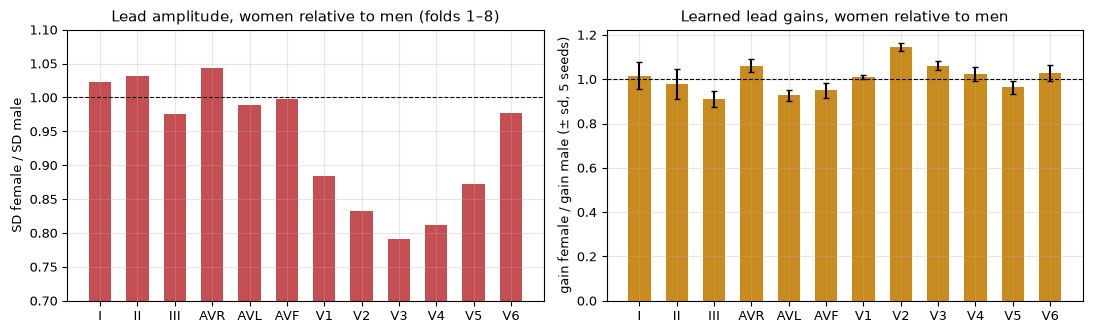

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.4))
x = np.arange(len(LEADS))
ax[0].bar(x, leads_table['amplitude F/M'], color='#C44E52', width=0.6)
ax[0].axhline(1, color='black', lw=0.8, ls='--')
ax[0].set_xticks(x, LEADS)
ax[0].set(ylim=(0.7, 1.1), ylabel='SD female / SD male', title='Lead amplitude, women relative to men (folds 1–8)')
if 'gain F/M' in leads_table:
    ax[1].bar(x, leads_table['gain F/M'], yerr=leads_table['gain F/M sd'], color='#C98A1E', width=0.6, capsize=2)
    ax[1].axhline(1, color='black', lw=0.8, ls='--')
    ax[1].set_xticks(x, LEADS)
    ax[1].set(ylabel='gain female / gain male (± sd, 5 seeds)', title='Learned lead gains, women relative to men')
plt.tight_layout()
plt.savefig(FIG_DIR + 'n5_leads.png', dpi=150)
plt.show()

In [8]:
json.dump({'summary': summary.reset_index().to_dict('records'), 'screening': sens.to_dict('records'),
           'leads': leads_table.reset_index().to_dict('records')},
          open(CACHE + 'n5_summary.json', 'w'), indent=1, default=float)
print('сохранено: n5_summary.json, n5_methods.png, n5_leads.png')

сохранено: n5_summary.json, n5_methods.png, n5_leads.png


## Выводы

**Общее качество.** Все варианты не хуже базового. Значимо лучше базового — FiLM (+0.0015 [+0.0003; +0.0028]) и
возраст/пол на входе головы (+0.0014 [+0.0005; +0.0023]); предлагаемое усиление отведений — +0.0012
[−0.0001; +0.0026], на границе значимости.

**Разрыв по полу: заранее заданный критерий выполнил только adversarial debiasing — и ценой мужчин.** Разрыв
macro-AUC сократился с −0.019 до −0.015 (разность значима), но за счёт снижения качества у мужчин (0.9416 →
0.9388) при неизменном у женщин (0.9226 → 0.9234): разрыв выравнивается «вниз», а не подтягиванием женщин.
По MI разрыв не сократил ни один вариант (от −0.022 до −0.024 у всех). Предлагаемое усиление отведений, FiLM,
нормировка по полу, возраст/пол на входе и веса по полу разрыв не меняют.

**Гипотеза амплитуды отвергнута.** У женщин грудные отведения V1–V5 на 12–21 % слабее, чем у мужчин, отведения
конечностей — нет. Нормировка статистикой своего пола полностью выравнивает амплитуды, но разрыв остаётся
прежним (−0.020); значит, разрыв не вызван масштабом сигнала.

**Что выучил модуль усиления отведений.** Устойчиво по всем 5 seed модуль усиливает у женщин относительно
мужчин V2 (в 1.15 ± 0.02 раза), V3 (1.06) и aVR (1.06) и ослабляет III (0.91) и aVL (0.93) — то есть сам
компенсирует часть дефицита амплитуды в правых грудных отведениях (для V2: 0.83 → 0.95). Модуль
интерпретируем и воспроизводим, но компенсация масштаба качества у женщин не повышает — в согласии с
результатом нормировки по полу.

**Скрининг.** При общем пороге методы, повышающие качество у мужчин (FiLM, усиление отведений), увеличивают
разрыв чувствительности к MI (−0.056 и −0.064 против −0.028 у базы). Пороги с равной чувствительностью
выравнивают её у всех вариантов (|разрыв| ≤ 0.012), и цена всегда одна — специфичность у женщин на 5–8 п. п.
ниже. Наименьшая цена — у adversarial debiasing (−0.049), снова за счёт мужчин.

**Итог двух экспериментов (8 вариантов × 5 seed).** Разрыв в различающей способности у женщин не устраняется ни
архитектурой (недели 7–8), ни демографическим контекстом, ни балансом вклада полов, ни учётом пола на уровне
отведений или каналов, ни выравниванием амплитуды; единственный метод, его сокращающий, делает это ухудшением
качества у мужчин. Это согласуется с данными моделирования, что анатомия женщин маскирует ЭКГ-признаки
инфаркта: информационное содержание женских ЭКГ при инфаркте ниже, и справедливость здесь достигается не
обучением, а решающим правилом — порогами с равной чувствительностью при явной цене в специфичности.